In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

$$x = A.sin(wt+\phi)$$

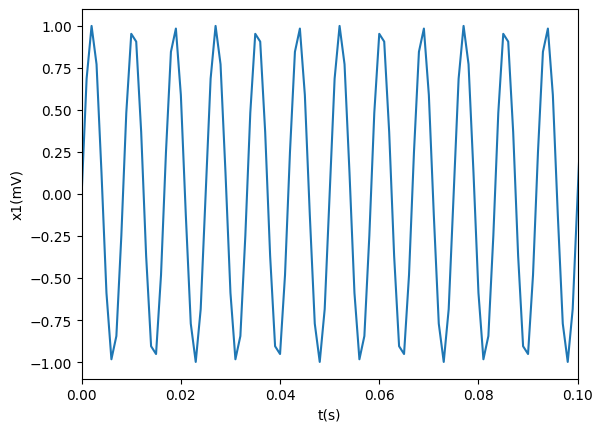

In [7]:
# @title {vertical-output:true}
f1 = 120
w1 = 2*np.pi*f1

A = 1
phi = 0

fs = 1e3
ts = 1/fs
n = np.arange(1000)
t = n*ts

x1 = A*np.sin(w1*t + phi)
plt.plot(t,x1)
plt.xlim(0,0.1)
plt.xlabel('t(s)')
plt.ylabel('x1(mV)')
plt.show()

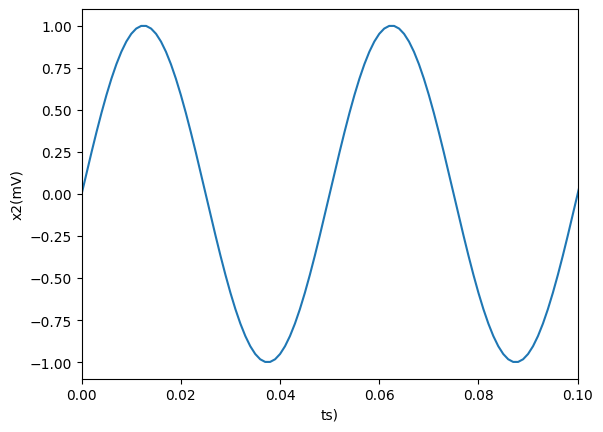

In [8]:
# @title {vertical-output:true}
f2 = 20
w2 = 2*np.pi*f2

A = 1
phi = 0

fs = 1e3
ts = 1/fs
n = np.arange(1000)
t = n*ts

x2 = A*np.sin(w2*t + phi)
plt.plot(t,x2)
plt.xlim(0,0.1)
plt.xlabel('ts)')
plt.ylabel('x2(mV)')
plt.show()

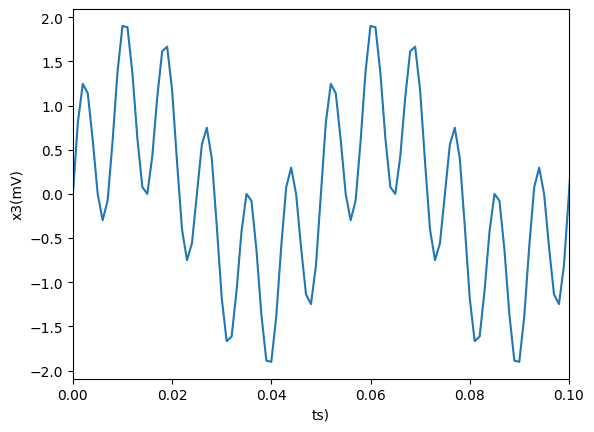

In [9]:
# @title {vertical-output:true}

x3 = x1 + x2

plt.plot(t,x3)
plt.xlim(0,0.1)
plt.xlabel('ts)')
plt.ylabel('x3(mV)')
plt.show()

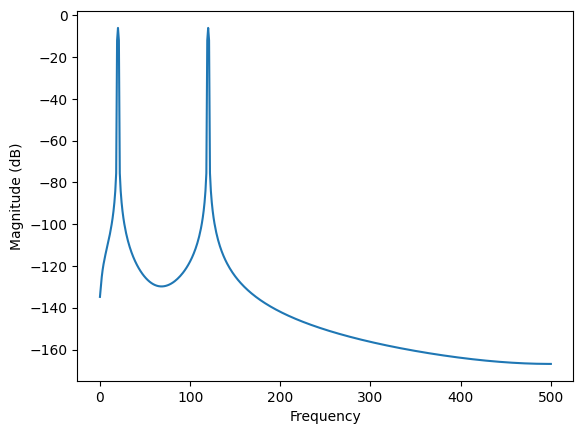

In [10]:
# @title {vertical-output:true}

plt.magnitude_spectrum(x3, scale="dB",Fs=fs)
plt.show()

In [21]:
sos = signal.butter(N=15, Wn=60, btype='hp', fs=1000, output='sos')

filtered = signal.sosfilt(sos, x3)

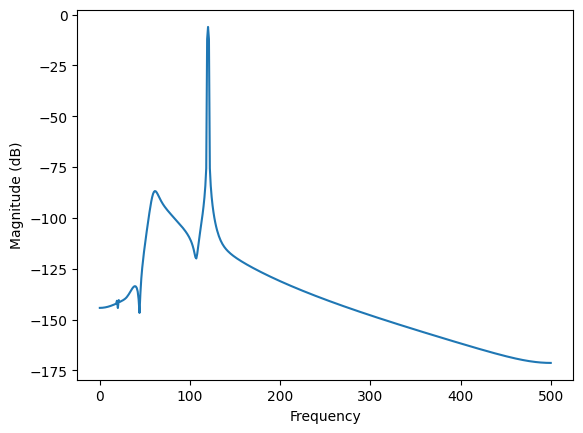

In [22]:
# @title {vertical-output:true}

plt.magnitude_spectrum(filtered, scale="dB",Fs=fs)
plt.show()

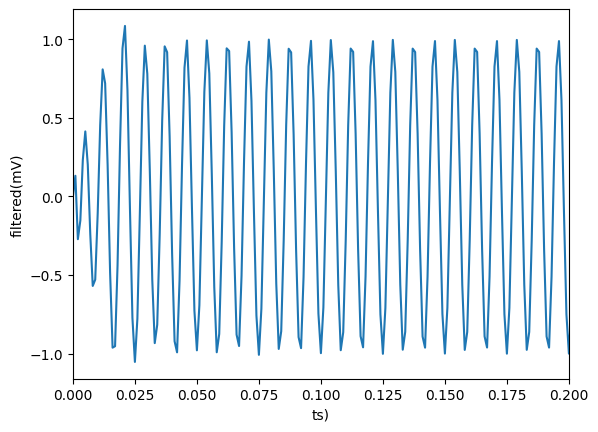

In [23]:
# @title {vertical-output:true}

plt.plot(t, filtered)
plt.xlim(0,0.2)
plt.xlabel('ts)')
plt.ylabel('filtered(mV)')
plt.show()

### Filtro FIR (Finite Impulse Response)

Un filtro FIR es un tipo de filtro digital cuya respuesta al impulso es de duración finita, lo que significa que el filtro se asienta en un tiempo finito en respuesta a una entrada de impulso. Esto contrasta con los filtros IIR (Infinite Impulse Response), que tienen una respuesta al impulso de duración infinita.

**Ventajas de los filtros FIR:**
* **Estabilidad inherente:** Los filtros FIR son siempre estables.
* **Fase lineal:** Pueden diseñarse para tener una fase exactamente lineal, lo cual es crucial en aplicaciones donde la distorsión de fase debe evitarse (por ejemplo, procesamiento de audio y video).
* **Diseño más sencillo:** El diseño de filtros FIR con propiedades específicas (como fase lineal) es relativamente más sencillo que con los filtros IIR.

Para diseñar un filtro FIR, comúnmente se utiliza el método de la ventana (como la ventana de Hamming, Blackman, etc.) o el método de muestreo de frecuencia.

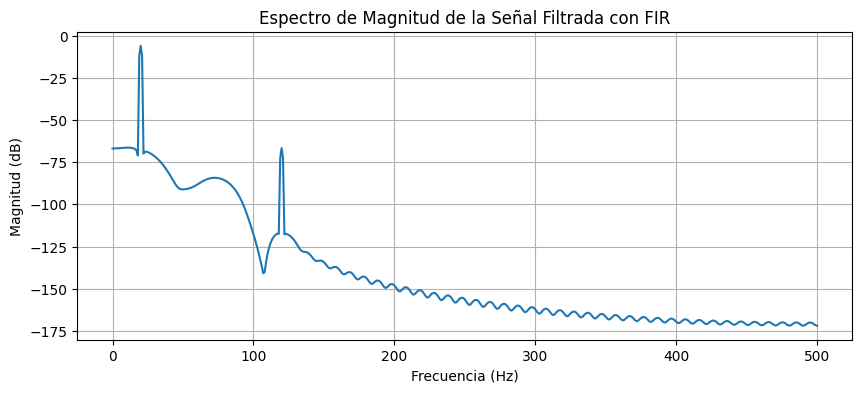

In [24]:
# @title {vertical-output:true}

# Definir los parámetros para el filtro FIR
# `numtaps`: Número de coeficientes (taps) del filtro. Un mayor número de taps generalmente da una transición más pronunciada y una mejor atenuación de la banda de rechazo.
# `cutoff`: Frecuencia de corte del filtro (normalizada por la frecuencia de Nyquist, fs/2). En este caso, un filtro paso bajo con corte en 80 Hz.
# `fs`: Frecuencia de muestreo.

# Crear un filtro FIR pasa-bajo
cutt_off = 80 # Hz
numtaps = 101 # número de taps

fir_filter = signal.firwin(numtaps, cutoff=cutt_off, fs=fs, pass_zero='lowpass')

# Aplicar el filtro FIR a la señal `x3`
filtered_fir = signal.lfilter(fir_filter, 1.0, x3)

# Visualizar el espectro de magnitud de la señal filtrada con FIR
plt.figure(figsize=(10, 4))
plt.magnitude_spectrum(filtered_fir, scale="dB", Fs=fs)
plt.title('Espectro de Magnitud de la Señal Filtrada con FIR')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Magnitud (dB)')
plt.grid(True)
plt.show()

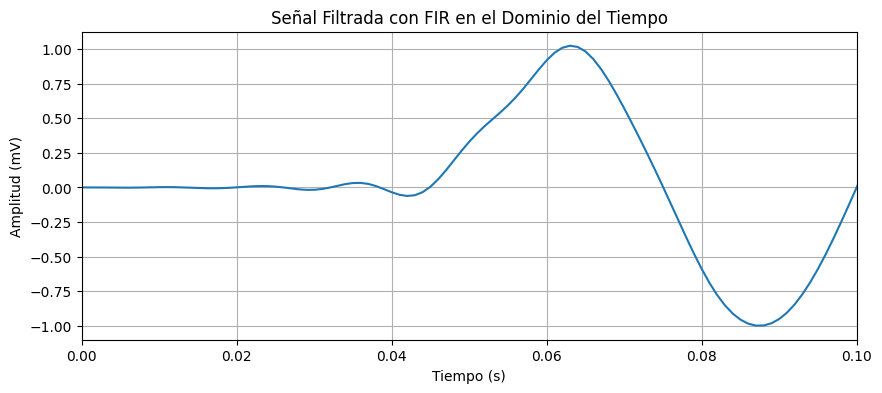

In [25]:
# @title {vertical-output:true}

# Visualizar la señal filtrada con FIR en el dominio del tiempo
plt.figure(figsize=(10, 4))
plt.plot(t, filtered_fir)
plt.xlim(0, 0.1) # Mostrar solo los primeros 0.1 segundos para una mejor visualización
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (mV)')
plt.title('Señal Filtrada con FIR en el Dominio del Tiempo')
plt.grid(True)
plt.show()